In [1]:
from sklearn.preprocessing import StandardScaler
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.cluster import KMeans
from sklearn.cluster import DBSCAN

## Fase 1: Exploración Inicial

In [11]:
df = pd.read_csv('logistica_baja_california.csv')
df.head()

,Latitud,Longitud,Tipo_Solicitud
0,32.520796,-116.992084,Recoleccion
1,32.566198,-117.046102,Recoleccion
2,32.461507,-117.062417,Viaje_Pasajero
3,32.510667,-117.023516,Viaje_Pasajero
4,32.498468,-117.019210,Viaje_Pasajero


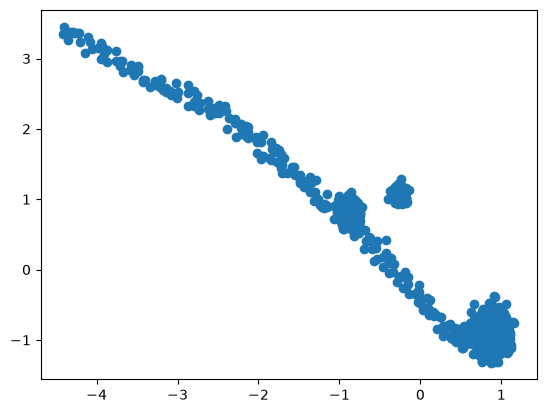

In [7]:
scaler = StandardScaler()
cols = ["Latitud", "Longitud"]
df_scaled = scaler.fit_transform(df[cols])
df_scaled = pd.DataFrame(df_scaled, columns=cols)
df_scaled.head()
plt.scatter(df_scaled["Latitud"], df_scaled["Longitud"])

## Fase 2: Misión Estratégica
Algoritmo: K- Means

[[  32.50631573 -117.03496385]
 [  31.04053982 -116.13802721]
 [  31.91234754 -116.58072818]]


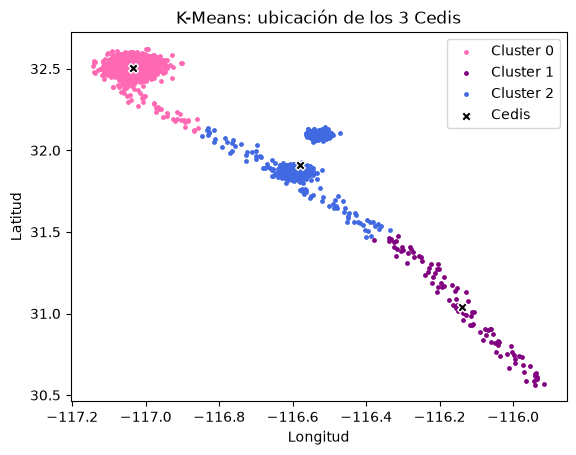

In [12]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

kmeans.fit(df_scaled)

df["Cluster"] = kmeans.labels_

# Regresar a grados
centros = scaler.inverse_transform(kmeans.cluster_centers_)
print(centros)

# Scatter de los clusters
colores = ["hotpink", "purple", "royalblue"]
for c, grupo in df.groupby("Cluster"):
    plt.scatter(grupo["Longitud"], grupo["Latitud"], s=6,
                color=colores[c], label=f"Cluster {c}")

plt.scatter(centros[:, 1], centros[:, 0], marker="X", s=50,
            color="black", edgecolor="white", label="Cedis")

plt.xlabel("Longitud"); plt.ylabel("Latitud")
plt.title("K-Means: ubicación de los 3 Cedis")
plt.legend(markerscale=1)
plt.show()

***1. ¿Dónde colocó el algoritmo que seleccionaron las Cedis? ¿Consideran que sus localizaciones hacen sentido?***

*   El cedis 0 tiene sentido por que cae en tijuana, en donde se encuentra la mayor demanda.
*   El cedis 2 tiene sentido porque queda en la zona de Ensenada, pero desplazado hacia el norte ya que tambien cuenta el Valle de Guadalupe
*   El cedis 1 no tiene mucho sentido ya que se ubica en medio de la nada, sin ninguna ciudad.


***2. ¿Por qué la matemática de este algoritmo provocó esto?***

K-Means minimiza la suma de distancias al cuadro entre cada punto y su centroide, y el centroide es el promedio de los puntos de su grupo.

## Fase 3: Misión Operativa (Mapa de Tráfico y Zonas Calientes)
Algoritmo: DBSCAN

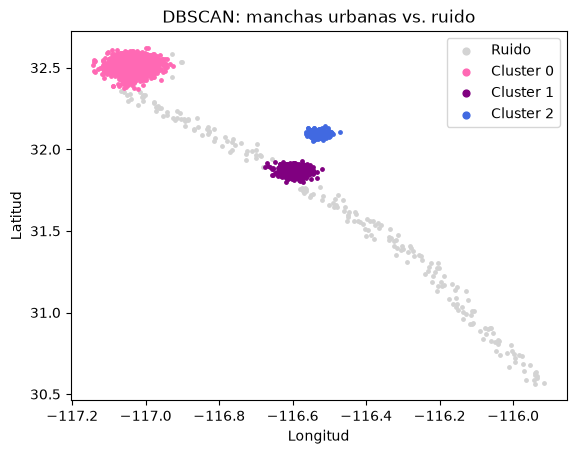

In [13]:
# eps = radio de vecindad; min_samples = vecinos mínimos para ser zona densa
df["Cluster"] = DBSCAN(eps=0.1, min_samples=20).fit_predict(df_scaled)

# Colores: ruido en gris, clusters en rosa, morado y azul
colores = {-1: "lightgray", 0: "hotpink", 1: "purple", 2: "royalblue"}
nombres = {-1: "Ruido", 0: "Cluster 0", 1: "Cluster 1", 2: "Cluster 2"}

# Pinta cada grupo con su color
for c, grupo in df.groupby("Cluster"):
    plt.scatter(grupo["Longitud"], grupo["Latitud"], s=6,
                color=colores[c], label=nombres[c])

plt.xlabel("Longitud"); plt.ylabel("Latitud")
plt.title("DBSCAN: manchas urbanas vs. ruido")
plt.legend(markerscale=2)
plt.show()

***1.**   **¿Usaron el mismo algoritmo que en la misión anterior?***

No, en la fase pasada usamos K-Means y en esta fase usamons DBSCAN.

***2.   ¿De no ser así, porqué se comportaron diferentes?***

K-Means agrupa por distancia a centroides y obliga a todos los puntos pertenecer a un cluster, mientras que DBSCAN agrupa por densidad.

***3.   ¿A qué ciudades reales corresponden las 3 manchas urbanas que encontró su algoritmo?***

El cluster 0 representa a Tijuana, el cluster 1 representa a Ensenada y el cluster 2 representa a Zona de Valle de Guadalupe/Tecate.